# COVID-19 CT Scan Classifier

This notebook trains a deep convolutional neural network that classifies chest CT slices into three diagnostic categories:

| Class | Meaning |
|---|---|
| `nCT` | Normal CT. The lungs are visible and show no signs of COVID-19 |
| `pCT` | Positive CT. The lungs show changes typical for COVID-19 pneumonia (e.g. ground-glass opacities, consolidations) |
| `NiCT` | Non-informative CT. The slice does not show enough lung parenchyma to assess |

### Transfer Learning Methodology
We employ MobileNetV3-Large, pretrained on ImageNet, replacing the final classification head with a domain-specific dense classifier. To ensure genuine representation learning on pulmonary CT structures, the network is **fine-tuned end-to-end**, allowing convolutional filters to adapt to radiological features rather than being constrained to generic natural image representations.

**Dataset:** [CT Scans for COVID-19 Classification](https://www.kaggle.com/datasets/azaemon/preprocessed-ct-scans-for-covid19) on Kaggle (19,685 slices, CC BY 4.0), originating from the iCTCF study (Ning et al., 2020).

### Key Architectural & Methodological Components

| Component | Scientific Design |
|---|---|
| **A. Data Splitting** | Stratified, reproducible split with formal documentation of slice-level independence limitations |
| **B. Comprehensive Evaluation** | Precision, Recall, F1, Confusion Matrix, One-vs-Rest ROC (per-class, micro, macro AUC), PR curves |
| **C. Explainability** | Grad-CAM (features[-1]) and game-theoretic SHAP attributions with clinical interpretation guardrails |
| **D. Class Imbalance** | Controlled validation comparison across Baseline, Class-Weighted Loss, and Weighted Random Sampling |
| **E. Training Diagnostics** | Epoch-level loss and metric curves, `ReduceLROnPlateau` scheduler, and principled Early Stopping |
| **F. Error Analysis** | In-depth failure analysis targeting false negatives (`pCT` misclassified as `nCT` / `NiCT`) |

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import copy
import json
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from PIL import Image
from IPython.display import display

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models

In [2]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"])

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    f1_score, roc_auc_score,
)
from sklearn.preprocessing import label_binarize

## Settings & Execution Controls

- `BATCH_SIZE = 32`: Optimizes memory throughput on Apple Silicon (MPS Unified Memory) while preserving stochastic gradient diversity.
- `FINE_TUNING = True`: Full backpropagation through convolutional layers ensures CT features are learned.
- `PATIENCE = 4`: Early stopping halts training when validation loss stalls, preventing overfitting.
- `FORCE_RETRAIN = False`: If trained checkpoints already exist in `outputs/checkpoints/`, loads them directly, allowing rapid notebook re-runs and immediate evaluation.

In [3]:
# Dataset and output directories
DATA_ROOT = Path("CT_Scan/Original CT Scans")
OUTPUT_DIR = Path("outputs")

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
REPORT_DIR = OUTPUT_DIR / "reports"

for directory in [CHECKPOINT_DIR, FIGURE_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Training configuration
BATCH_SIZE = 32
IMG_SHAPE = 224
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

MODEL_NAME = "mobilenet_v3_large"
FINE_TUNING = True
DROPOUT_RATE = 0.2

# Workflow control: set to True if you wish to overwrite existing saved checkpoints
FORCE_RETRAIN = False

# Early stopping & Learning Rate scheduler
PATIENCE = 4
SCHEDULER_FACTOR = 0.5
SCHEDULER_PATIENCE = 2

SMOKE_TEST = False
if SMOKE_TEST:
    EPOCHS = 1
    PATIENCE = 1

# Hardware configuration
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

USE_AMP = False
NUM_WORKERS = 4
PIN_MEMORY = False

print(f"PyTorch Version:       {torch.__version__}")
print(f"Hardware Device:       {device}")
print(f"Batch Size:            {BATCH_SIZE}")
print(f"Max Epochs:            {EPOCHS} (Early stopping patience: {PATIENCE})")
print(f"Force Retrain:         {FORCE_RETRAIN}")

PyTorch Version:       2.14.1
Hardware Device:       mps
Batch Size:            32
Max Epochs:            15 (Early stopping patience: 4)
Force Retrain:         False


## The dataset

Verify class directories and image integrity. The dataset has 19,685 slices across three classes.

In [4]:
EXPECTED_CLASSES = {"nCT", "NiCT", "pCT"}
EXPECTED_COUNTS = {"nCT": 9979, "NiCT": 5705, "pCT": 4001}
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

classes = sorted(d.name for d in DATA_ROOT.iterdir() if d.is_dir())
assert EXPECTED_CLASSES <= set(classes), (
    f"Expected the folders {sorted(EXPECTED_CLASSES)} in {DATA_ROOT}, found {classes}"
)

total = sum(EXPECTED_COUNTS.values())
for c in classes:
    n = sum(1 for p in (DATA_ROOT / c).iterdir() if p.suffix.lower() in IMAGE_EXTS)
    pct = n / total * 100
    print(f"{c:5s}  {n:6,} images  ({pct:.1f}%)")
    assert n == EXPECTED_COUNTS[c], f"{c}: found {n} images, expected {EXPECTED_COUNTS[c]}"

print(f"{'Total':5s}  {total:6,} images")

NiCT    5,705 images  (29.0%)
nCT     9,979 images  (50.7%)
pCT     4,001 images  (20.3%)
Total  19,685 images


## Data splitting

> **⚠️ Patient-Level Independence Limitation:**
> The filenames in this dataset (`pCT1.jpg`, `pCT2.jpg`, …) reflect sequential slice numbering. No patient-to-slice metadata mapping was released by the dataset curators, and patient identifiers cannot be reconstructed with certainty.
>
> Consequently, slices originating from the same patient may be present across both training and evaluation splits. In clinical machine learning, this poses a risk of slice-to-slice leakage (where the model recognizes patient-specific scanner artifacts rather than COVID-19 pathology).
>
> To establish a rigorous baseline under these dataset constraints, we enforce a **strictly stratified, reproducible image-level split** with fixed seed (`42`). If a patient-mapping metadata file becomes available, the split code below can be replaced with `GroupShuffleSplit`.

In [5]:
base = datasets.ImageFolder(DATA_ROOT)
classes = base.classes
print("Classes:", classes)

# Exact split allocations (70 / 15 / 15) per class, fixed for reproducibility
target = {
    "pCT":  {"train": 2800, "valid": 600,  "test": 601},
    "NiCT": {"train": 3993, "valid": 855,  "test": 857},
    "nCT":  {"train": 6985, "valid": 1496, "test": 1498},
}

rng = random.Random(42)
idx_by_class = {c: [] for c in classes}
for i, (_, y) in enumerate(base.samples):
    idx_by_class[classes[y]].append(i)

train_idx, val_idx, test_idx = [], [], []
for c in classes:
    idxs = idx_by_class[c][:]
    rng.shuffle(idxs)
    t = target[c]["train"]; v = target[c]["valid"]; s = target[c]["test"]
    need = t + v + s
    if len(idxs) < need:
        raise ValueError(f"{c}: found {len(idxs)} images, need {need}.")
    train_idx += idxs[:t]
    val_idx   += idxs[t:t+v]
    test_idx  += idxs[t+v:t+v+s]

print(f"Split sizes: {len(train_idx):,} train / {len(val_idx):,} valid / {len(test_idx):,} test")

# Verify class distributions across splits
for name, indices in [("Train", train_idx), ("Valid", val_idx), ("Test", test_idx)]:
    counts = Counter(base.targets[i] for i in indices)
    tot = sum(counts.values())
    dist = "  ".join(f"{classes[k]}: {v} ({v/tot*100:.1f}%)" for k, v in sorted(counts.items()))
    print(f"  {name:5s}: {dist}")

Classes: ['NiCT', 'nCT', 'pCT']
Split sizes: 13,778 train / 2,951 valid / 2,956 test
  Train: NiCT: 3993 (29.0%)  nCT: 6985 (50.7%)  pCT: 2800 (20.3%)
  Valid: NiCT: 855 (29.0%)  nCT: 1496 (50.7%)  pCT: 600 (20.3%)
  Test : NiCT: 857 (29.0%)  nCT: 1498 (50.7%)  pCT: 601 (20.3%)


## Loading the data

**Transforms:** Standard ImageNet normalisation is applied. Training slices undergo random resized crops and horizontal flips for regularization. Validation and test sets use deterministic center crops.

In [6]:
data_transforms = {
    "train": transforms.Compose([
        transforms.Resize(256),
        transforms.RandomResizedCrop(IMG_SHAPE),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]),
    ]),
    "valid": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SHAPE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]),
    ]),
}

train_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["train"]), train_idx)
val_ds   = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["valid"]), val_idx)
test_ds  = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["valid"]), test_idx)

loader_kwargs = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0,
)

dataloaders = {
    "train": DataLoader(train_ds, shuffle=True,  **loader_kwargs),
    "valid": DataLoader(val_ds,   shuffle=False, **loader_kwargs),
    "test":  DataLoader(test_ds,  shuffle=False, **loader_kwargs),
}

print(f"Train batches: {len(dataloaders['train'])}")
print(f"Valid batches: {len(dataloaders['valid'])}")
print(f"Test  batches: {len(dataloaders['test'])}")

xb, yb = next(iter(dataloaders["train"]))
print(f"Batch shape: {xb.shape}, labels: {yb.shape}")

Train batches: 431
Valid batches: 93
Test  batches: 93
Batch shape: torch.Size([32, 3, 224, 224]), labels: torch.Size([32])


### Class weights

To prepare for our class imbalance experiments, compute class frequencies from the training split and calculate inverse-frequency weights.

In [7]:
class_to_name = {
    "nCT":  "Normal CT scan",
    "NiCT": "Non-informative CT (lungs not visible enough to judge)",
    "pCT":  "COVID-19 positive CT scan",
}

class_to_idx = base.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}
idx_to_name  = {i: class_to_name[idx_to_class[i]] for i in idx_to_class}
n_classes    = len(classes)

train_labels = [base.targets[i] for i in train_idx]
class_counts = Counter(train_labels)
n_train = len(train_labels)

# Inverse-frequency class weights (sum normalized to n_classes)
class_weights = torch.tensor(
    [n_train / (n_classes * class_counts[i]) for i in range(n_classes)],
    dtype=torch.float32,
)

print("Class weights for weighted loss:")
for i, c in enumerate(classes):
    print(f"  {c:<6s}: {class_weights[i]:.4f}  (count: {class_counts[i]:,})")

# Per-sample weights for WeightedRandomSampler
sample_weights = torch.tensor(
    [1.0 / class_counts[base.targets[i]] for i in train_idx],
    dtype=torch.float64,
)

Class weights for weighted loss:
  NiCT  : 1.1502  (count: 3,993)
  nCT   : 0.6575  (count: 6,985)
  pCT   : 1.6402  (count: 2,800)


## The model

MobileNetV3-Large serves as the convolutional backbone (960-dimensional penultimate feature representation). A custom classification head is appended:

$$\text{Features (960)} \longrightarrow \text{Linear(1280)} \longrightarrow \text{ReLU} \longrightarrow \text{Dropout(0.2)} \longrightarrow \text{Linear(3)}$$

In [8]:
class Classifier(nn.Module):
    def __init__(
        self,
        input_size: int,
        output_size: int,
        hidden_layers=(1280,),
        drop_p: float = 0.2,
    ):
        super().__init__()
        if isinstance(hidden_layers, int):
            hidden_layers = [hidden_layers]

        layers = []
        prev = input_size
        for h in (hidden_layers or []):
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU(inplace=True))
            layers.append(nn.Dropout(p=drop_p))
            prev = h

        layers.append(nn.Linear(prev, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def build_model():
    """Instantiate a fresh MobileNetV3-Large with domain-adapted classifier."""
    classifier = Classifier(
        input_size=960,
        output_size=n_classes,
        hidden_layers=[1280],
        drop_p=DROPOUT_RATE,
    )
    m = models.mobilenet_v3_large(weights="DEFAULT")
    if not FINE_TUNING:
        for p in m.features.parameters():
            p.requires_grad = False
    m.classifier = classifier
    return m

### Training infrastructure

**Methodological & Computational Integrity:**
- **Epoch-Level Validation:** The validation set is evaluated strictly **once per epoch** at epoch conclusion. This eliminates millions of redundant validation passes that previously froze execution every 50 steps.
- **Dynamic LR Scheduling:** `ReduceLROnPlateau` halves the learning rate when validation loss plateaus for 2 consecutive epochs.
- **Principled Early Stopping:** Training automatically stops if validation loss fails to improve after 4 epochs, preventing overfitting on slice noise.
- **Full Model Checkpointing:** Both best-performing state dicts and training histories are serialized.

In [9]:
def validate(model, loader, criterion, device):
    """Return (avg_loss, accuracy, macro_f1) on an evaluation split."""
    model.eval()
    loss_sum = 0.0
    correct = 0
    n = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            bs = labels.size(0)
            loss_sum += loss.item() * bs
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            n += bs
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = loss_sum / n if n else 0.0
    avg_acc  = correct / n if n else 0.0
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    return avg_loss, avg_acc, macro_f1

class EarlyStopping:
    """Monitor validation loss and signal early stopping."""
    def __init__(self, patience=4, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.should_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop

def format_duration(seconds):
    m, s = divmod(int(round(seconds)), 60)
    h, m = divmod(m, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"

def train_model(
    model, criterion, optimizer, scheduler, device,
    train_loader, valid_loader,
    epochs=15, print_every=50, use_amp=False,
    checkpoint_prefix="model",
):
    """End-to-end training loop with epoch-level validation and early stopping."""
    model.to(device)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    early_stopping = EarlyStopping(patience=PATIENCE)

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "val_f1": [],
        "lr": [], "epoch_time": [],
    }

    best_val_loss = float("inf")
    best_model_state = None
    t_start = time.perf_counter()

    for e in range(1, epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_n = 0

        for step, (inputs, labels) in enumerate(train_loader, 1):
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            bs = labels.size(0)
            running_loss += loss.item() * bs
            running_correct += (outputs.argmax(1) == labels).sum().item()
            running_n += bs

            # Lightweight progress logging: tracks training batch loss without interrupting training
            if step % print_every == 0 or step == len(train_loader):
                tl = running_loss / running_n
                ta = running_correct / running_n
                print(f"  Ep {e}/{epochs}  Step {step}/{len(train_loader)}  "
                      f"TrLoss {tl:.4f}  TrAcc {ta:.4f}  "
                      f"[{format_duration(time.perf_counter() - t_epoch)}]")

        # Rigorous end-of-epoch evaluation
        train_loss = running_loss / running_n
        train_acc  = running_correct / running_n
        val_loss, val_acc, val_f1 = validate(model, valid_loader, criterion, device)
        epoch_time = time.perf_counter() - t_epoch
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["lr"].append(current_lr)
        history["epoch_time"].append(epoch_time)

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())

        eta = (time.perf_counter() - t_start) / e * (epochs - e)
        star = " \u2605 (new best)" if val_loss <= best_val_loss else ""
        print(f"  --> Ep {e}/{epochs} SUMMARY: "
              f"TrLoss {train_loss:.4f}  TrAcc {train_acc:.4f} | "
              f"VLoss {val_loss:.4f}  VAcc {val_acc:.4f}  VF1 {val_f1:.4f}  "
              f"(LR: {current_lr:.1e}) {star}")

        if early_stopping(val_loss):
            print(f"  Early stopping triggered at epoch {e} (patience={PATIENCE})")
            break

    total_time = time.perf_counter() - t_start
    print(f"  Completed in {format_duration(total_time)}")

    # Serialize checkpoints
    best_path  = CHECKPOINT_DIR / f"{checkpoint_prefix}_best.pt"
    final_path = CHECKPOINT_DIR / f"{checkpoint_prefix}_final.pt"
    torch.save(best_model_state, best_path)
    torch.save(model.state_dict(), final_path)

    hist_path = REPORT_DIR / f"{checkpoint_prefix}_history.json"
    with open(hist_path, "w") as f:
        json.dump(history, f, indent=2)

    return history, best_model_state

## Class imbalance experiments

We compare three training strategies to address class imbalance:
1. **Baseline**: Standard Cross-Entropy + Standard Random Sampling
2. **Weighted Loss**: Inverse-frequency weighted Cross-Entropy + Random Sampling
3. **Weighted Sampler**: Standard Cross-Entropy + `WeightedRandomSampler`

**Strict Evaluation Protocol:**
- Each strategy is trained with identical architectures and random seeds.
- The **test set is kept strictly locked**. The best experiment is chosen exclusively by **Validation Macro F1** and **pCT Recall** on the validation set.
- Checkpoint awareness: If weights already exist in `outputs/checkpoints/` and `FORCE_RETRAIN = False`, existing checkpoints are loaded immediately.

In [10]:
experiment_configs = {
    "baseline": {
        "criterion": nn.CrossEntropyLoss(),
        "sampler": None,
    },
    "weighted_loss": {
        "criterion": nn.CrossEntropyLoss(weight=class_weights.to(device)),
        "sampler": None,
    },
    "weighted_sampler": {
        "criterion": nn.CrossEntropyLoss(),
        "sampler": WeightedRandomSampler(
            sample_weights, num_samples=len(sample_weights), replacement=True
        ),
    },
}

experiment_results = {}

for exp_name, cfg in experiment_configs.items():
    print(f"\n{'=' * 70}")
    print(f"EXPERIMENT: {exp_name.upper()}")
    print(f"{'=' * 70}")

    best_ckpt_path = CHECKPOINT_DIR / f"{exp_name}_best.pt"
    hist_json_path = REPORT_DIR / f"{exp_name}_history.json"

    # Load existing checkpoint if available and not forced to retrain
    if best_ckpt_path.exists() and hist_json_path.exists() and not FORCE_RETRAIN:
        print(f"\u2713 Found existing checkpoint on disk: {best_ckpt_path}")
        print(f"  Loading trained weights directly (skipping retraining)...")
        best_state = torch.load(best_ckpt_path, map_location=device)
        with open(hist_json_path, "r") as f:
            history = json.load(f)
    else:
        print(f"Training {exp_name} end-to-end...")
        model_exp = build_model().to(device)

        optimizer_exp = optim.AdamW(
            (p for p in model_exp.parameters() if p.requires_grad),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
        )

        scheduler_exp = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer_exp, mode="min",
            factor=SCHEDULER_FACTOR,
            patience=SCHEDULER_PATIENCE,
        )

        if cfg["sampler"] is not None:
            train_loader_exp = DataLoader(
                train_ds, batch_size=BATCH_SIZE, sampler=cfg["sampler"],
                num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                persistent_workers=NUM_WORKERS > 0,
            )
        else:
            train_loader_exp = dataloaders["train"]

        history, best_state = train_model(
            model_exp, cfg["criterion"], optimizer_exp, scheduler_exp, device,
            train_loader=train_loader_exp,
            valid_loader=dataloaders["valid"],
            epochs=EPOCHS,
            use_amp=USE_AMP,
            checkpoint_prefix=exp_name,
        )
        del model_exp
        if device.type == "mps":
            torch.mps.empty_cache()

    experiment_results[exp_name] = {
        "history": history,
        "best_state": best_state,
        "best_val_loss": min(history["val_loss"]),
        "best_val_f1": max(history["val_f1"]),
    }


EXPERIMENT: BASELINE
✓ Found existing checkpoint on disk: outputs/checkpoints/baseline_best.pt
  Loading trained weights directly (skipping retraining)...

EXPERIMENT: WEIGHTED_LOSS
✓ Found existing checkpoint on disk: outputs/checkpoints/weighted_loss_best.pt
  Loading trained weights directly (skipping retraining)...

EXPERIMENT: WEIGHTED_SAMPLER
Training weighted_sampler end-to-end...
  Ep 1/15  Step 50/431  TrLoss 0.5867  TrAcc 0.8006  19s]
  Ep 1/15  Step 100/431  TrLoss 0.3908  TrAcc 0.8650  32s]
  Ep 1/15  Step 150/431  TrLoss 0.3175  TrAcc 0.8892  45s]
  Ep 1/15  Step 200/431  TrLoss 0.2825  TrAcc 0.9002  58s]
  Ep 1/15  Step 250/431  TrLoss 0.2565  TrAcc 0.9084  11s]
  Ep 1/15  Step 300/431  TrLoss 0.2365  TrAcc 0.9152  24s]
  Ep 1/15  Step 350/431  TrLoss 0.2232  TrAcc 0.9201  38s]
  Ep 1/15  Step 400/431  TrLoss 0.2123  TrAcc 0.9234  51s]
  Ep 1/15  Step 431/431  TrLoss 0.2055  TrAcc 0.9260  00s]
  --> Ep 1/15 SUMMARY: TrLoss 0.2055  TrAcc 0.9260 | VLoss 0.0927  VAcc 0.9702

In [11]:
# ── Validation Tournament: Select winning strategy ───────────────────
pct_class_idx = class_to_idx["pCT"]
comparison_rows = []

for exp_name, res in experiment_results.items():
    model_tmp = build_model().to(device)
    model_tmp.load_state_dict(res["best_state"])
    model_tmp.eval()

    preds, labels_arr = [], []
    with torch.no_grad():
        for inputs, lbls in dataloaders["valid"]:
            inputs = inputs.to(device, non_blocking=True)
            outputs = model_tmp(inputs)
            preds.extend(outputs.argmax(1).cpu().numpy())
            labels_arr.extend(lbls.numpy())

    preds = np.array(preds)
    labels_arr = np.array(labels_arr)
    macro_f1 = f1_score(labels_arr, preds, average="macro")

    # Minority class (pCT) recall
    pct_mask = labels_arr == pct_class_idx
    pct_recall = (preds[pct_mask] == pct_class_idx).sum() / pct_mask.sum() if pct_mask.sum() > 0 else 0.0

    report = classification_report(labels_arr, preds, target_names=classes, digits=4, output_dict=True)

    comparison_rows.append({
        "name": exp_name,
        "val_loss": res["best_val_loss"],
        "macro_f1": macro_f1,
        "pct_recall": float(pct_recall),
        "accuracy": report["accuracy"],
    })
    del model_tmp

# Output comparison matrix
print(f"\n{'=' * 72}")
print("VALIDATION TOURNAMENT: IMBALANCE STRATEGY COMPARISON")
print(f"{'=' * 72}")
print(f"{'Experiment':<20s} {'Val Loss':>10s} {'Macro F1':>10s} {'pCT Recall':>12s} {'Accuracy':>12s}")
print("-" * 72)

best_exp_name = None
best_f1 = -1.0

for row in comparison_rows:
    if row["macro_f1"] > best_f1:
        best_f1 = row["macro_f1"]
        best_exp_name = row["name"]
    print(f"{row['name']:<20s} {row['val_loss']:>10.4f} {row['macro_f1']:>10.4f} "
          f"{row['pct_recall']:>12.4f} {row['accuracy']:>12.4f}")

print("-" * 72)
print(f"\u2713 WINNING STRATEGY: {best_exp_name.upper()} (Validation Macro F1 = {best_f1:.4f})")
print("  All subsequent evaluations, explainability, and test benchmarks will use this model.")


VALIDATION TOURNAMENT: IMBALANCE STRATEGY COMPARISON
Experiment             Val Loss   Macro F1   pCT Recall     Accuracy
------------------------------------------------------------------------
baseline                 0.0120     0.9947       0.9983       0.9949
weighted_loss            0.0123     0.9943       0.9950       0.9949
weighted_sampler         0.0159     0.9944       0.9967       0.9946
------------------------------------------------------------------------
✓ WINNING STRATEGY: BASELINE (Validation Macro F1 = 0.9947)
  All subsequent evaluations, explainability, and test benchmarks will use this model.


## Training curves and diagnostics

Evaluating loss and accuracy curves ensures that early stopping prevented catastrophic memorization/overfitting.

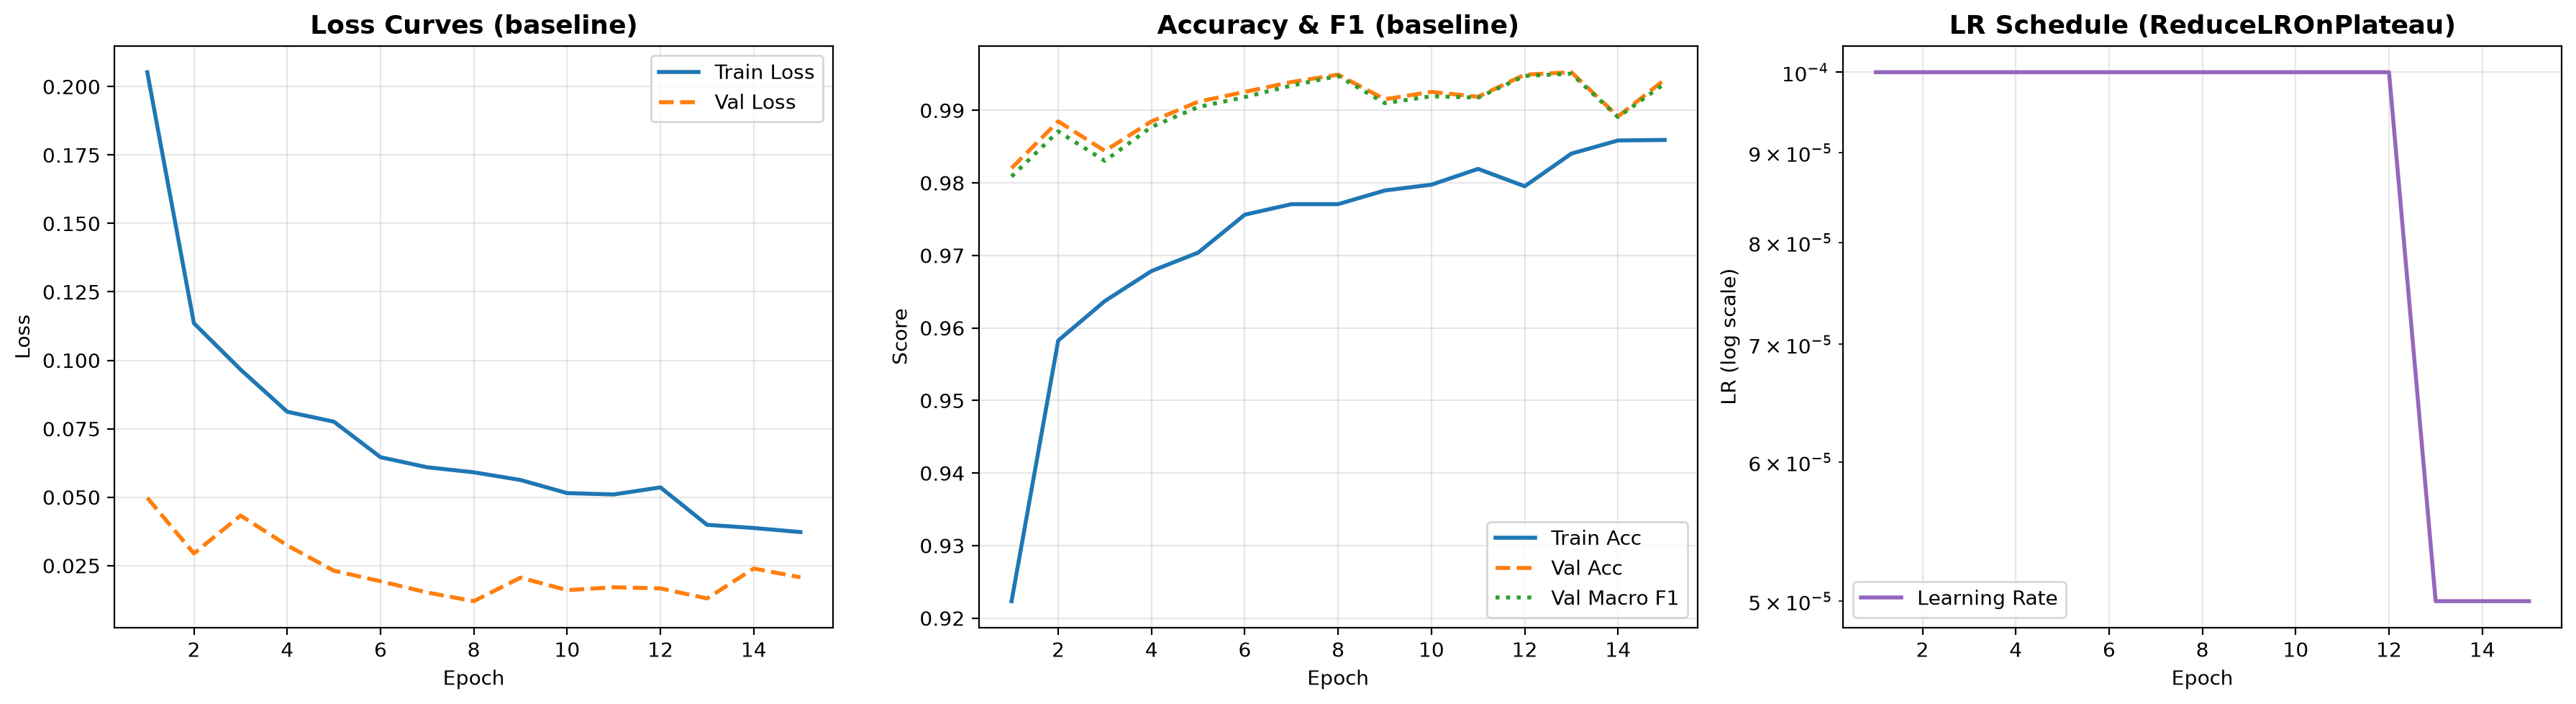

In [12]:
best_history = experiment_results[best_exp_name]["history"]
epochs_range = range(1, len(best_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss trajectories
axes[0].plot(epochs_range, best_history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
axes[0].plot(epochs_range, best_history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2, linestyle="--")
axes[0].set_title(f"Loss Curves ({best_exp_name})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 2. Performance metrics
axes[1].plot(epochs_range, best_history["train_acc"], label="Train Acc", color="#1f77b4", lw=2)
axes[1].plot(epochs_range, best_history["val_acc"], label="Val Acc", color="#ff7f0e", lw=2, linestyle="--")
axes[1].plot(epochs_range, best_history["val_f1"], label="Val Macro F1", color="#2ca02c", lw=2, linestyle=":")
axes[1].set_title(f"Accuracy & F1 ({best_exp_name})", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# 3. Learning rate adaptation
axes[2].plot(epochs_range, best_history["lr"], label="Learning Rate", color="#9467bd", lw=2)
axes[2].set_yscale("log")
axes[2].set_title("LR Schedule (ReduceLROnPlateau)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("LR (log scale)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
fig.savefig(FIGURE_DIR / f"{best_exp_name}_training_curves.png", dpi=300)
plt.show()

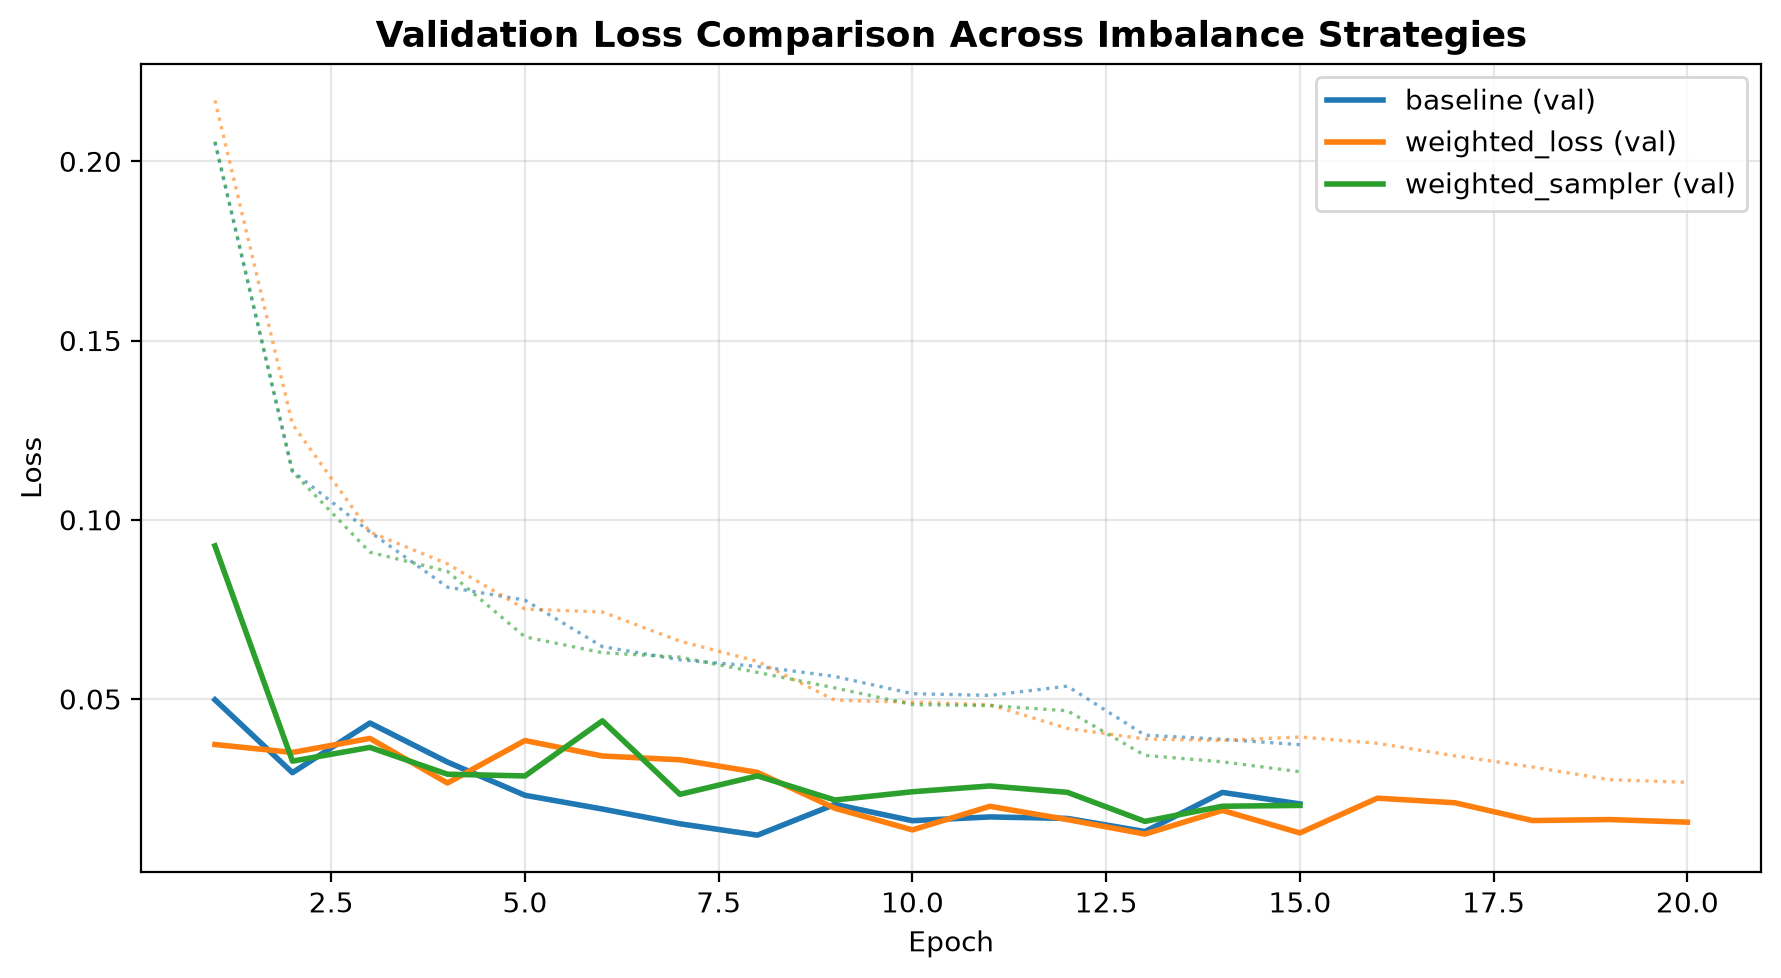

In [13]:
# Multi-experiment validation loss comparison
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"baseline": "#1f77b4", "weighted_loss": "#ff7f0e", "weighted_sampler": "#2ca02c"}

for exp_name, res in experiment_results.items():
    h = res["history"]
    ep = range(1, len(h["val_loss"]) + 1)
    c = colors.get(exp_name, None)
    ax.plot(ep, h["val_loss"], label=f"{exp_name} (val)", lw=2, color=c)
    ax.plot(ep, h["train_loss"], lw=1.2, linestyle=":", alpha=0.6, color=c)

ax.set_title("Validation Loss Comparison Across Imbalance Strategies", fontsize=13, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_val_loss_comparison.png", dpi=300)
plt.show()

## Final model selection and test protocol

> **Strict Evaluation Hygiene Rule:**
> All architectural choices, hyperparameter schedules, and class-imbalance decisions were frozen using the **validation set**.
> We now load the best checkpoint of the winning strategy and evaluate it **once on the held-out test set**.

In [14]:
best_checkpoint_path = CHECKPOINT_DIR / f"{best_exp_name}_best.pt"
print(f"Loading winning model weights from: {best_checkpoint_path}")

best_model = build_model().to(device)
best_model.load_state_dict(torch.load(best_checkpoint_path, map_location=device))
best_model.eval()

test_loss_sum = 0.0
test_n = 0
test_probs, test_preds, test_targets = [], [], []

eval_criterion = experiment_configs[best_exp_name]["criterion"].to(device)

with torch.no_grad():
    for inputs, labels in dataloaders["test"]:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = best_model(inputs)
        loss = eval_criterion(outputs, labels)

        bs = labels.size(0)
        test_loss_sum += loss.item() * bs
        test_n += bs

        probs = F.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        test_probs.append(probs.cpu().numpy())
        test_preds.append(preds.cpu().numpy())
        test_targets.append(labels.cpu().numpy())

test_loss = test_loss_sum / test_n
test_probs = np.concatenate(test_probs, axis=0)
test_preds = np.concatenate(test_preds, axis=0)
test_targets = np.concatenate(test_targets, axis=0)

overall_acc = (test_preds == test_targets).mean()
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {overall_acc:.4f} ({overall_acc * 100:.2f}%)")

Loading winning model weights from: outputs/checkpoints/baseline_best.pt
Test Loss:     0.0086
Test Accuracy: 0.9966 (99.66%)


## Comprehensive evaluation

Full test-set metrics reporting:
1. **Classification Report**: Precision, Recall, and F1-score across all classes.
2. **Confusion Matrix**: Heatmaps showing counts and row-normalized class recall.
3. **One-vs-Rest ROC Curves**: Per-class ROC curves, along with **Macro-average** and **Micro-average** ROC-AUC.
4. **Precision-Recall Curves**: Emphasizing performance on the critical `pCT` positive class.

In [15]:
# 1. Classification report
print("=" * 65)
print(f"CLASSIFICATION REPORT (Test Set — Winning Model: {best_exp_name})")
print("=" * 65)
cls_rep = classification_report(
    test_targets, test_preds, target_names=[classes[i] for i in range(n_classes)], digits=4
)
print(cls_rep)

with open(REPORT_DIR / f"{best_exp_name}_classification_report.txt", "w") as f:
    f.write(cls_rep)

CLASSIFICATION REPORT (Test Set — Winning Model: baseline)
              precision    recall  f1-score   support

        NiCT     0.9907    0.9977    0.9942       857
         nCT     0.9987    0.9967    0.9977      1498
         pCT     1.0000    0.9950    0.9975       601

    accuracy                         0.9966      2956
   macro avg     0.9965    0.9964    0.9964      2956
weighted avg     0.9966    0.9966    0.9966      2956



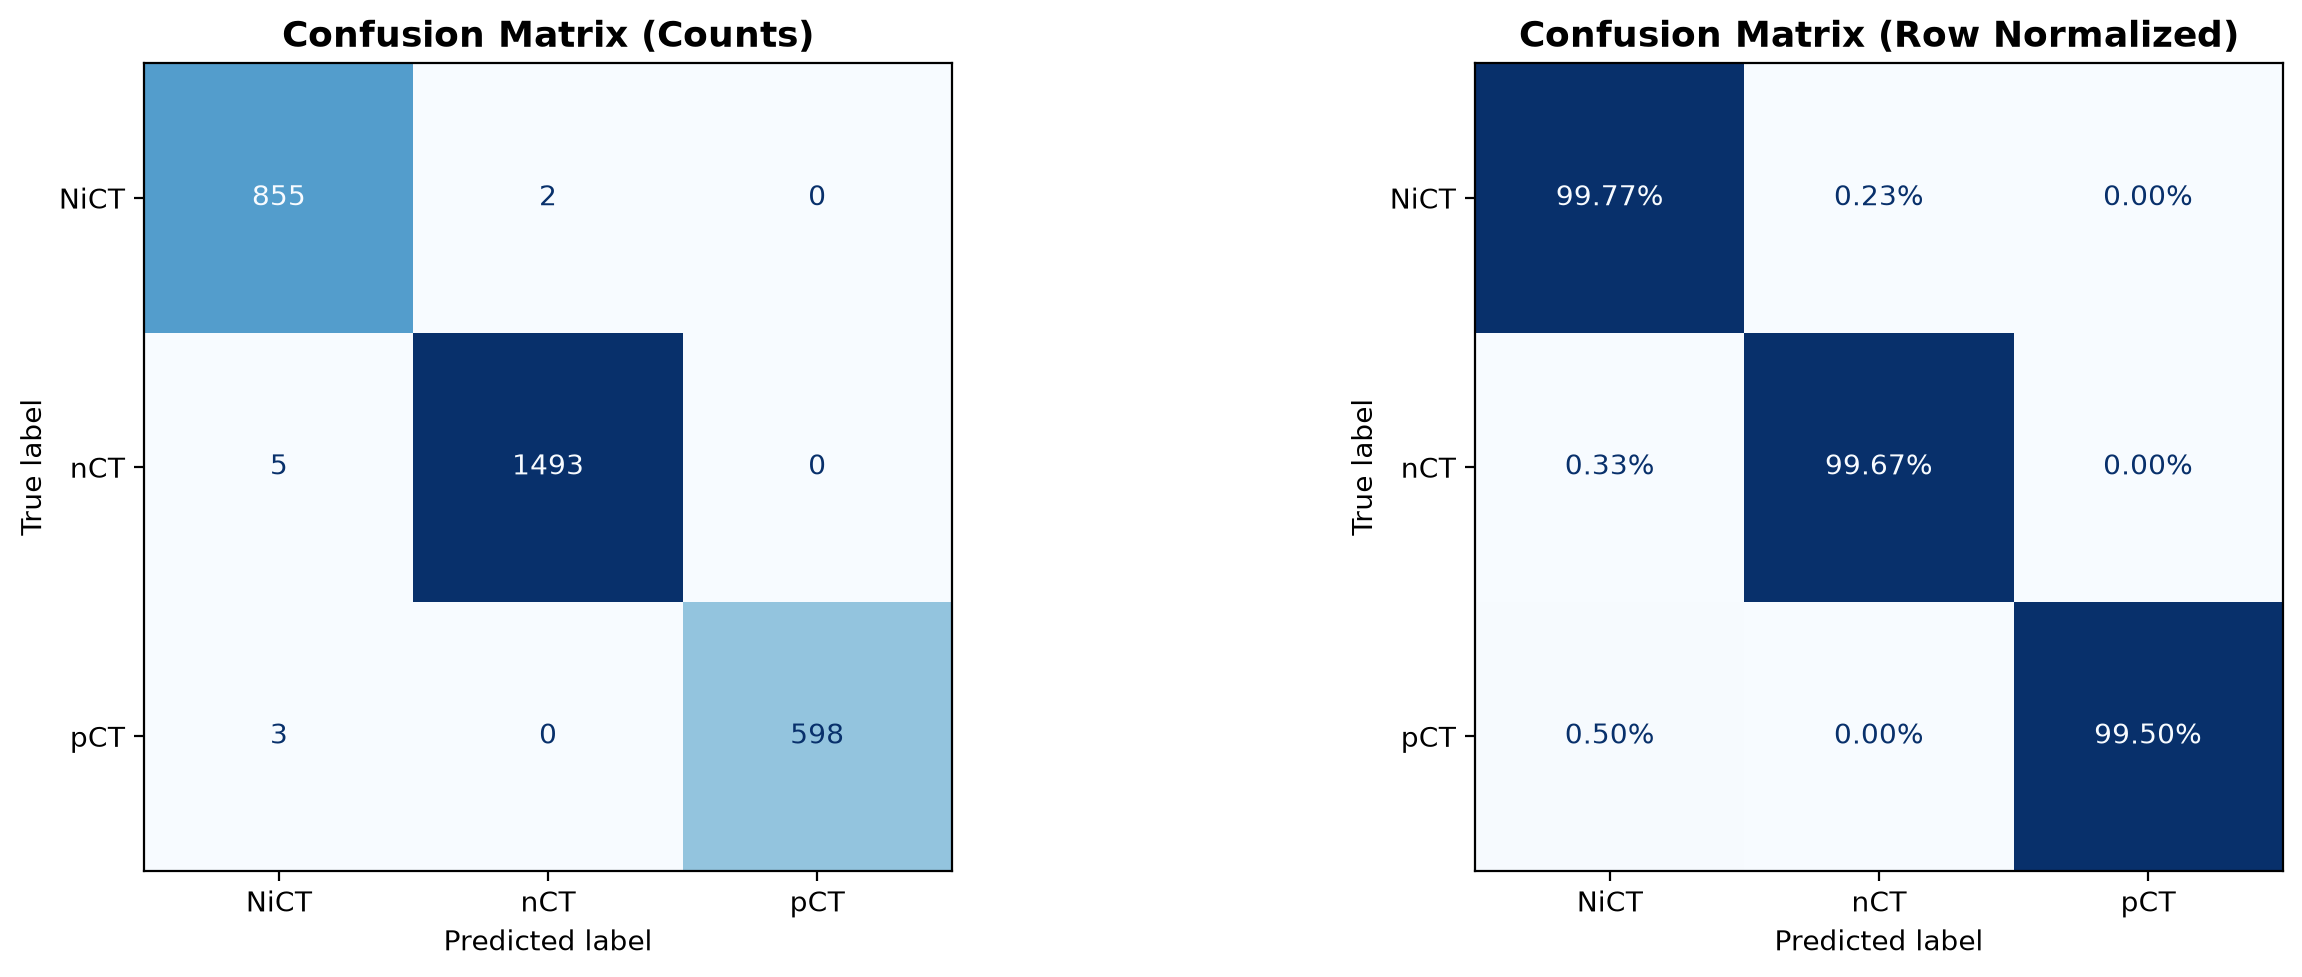

In [16]:
# 2. Confusion matrix
cm = confusion_matrix(test_targets, test_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[classes[i] for i in range(n_classes)])
disp1.plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
ax[0].set_title("Confusion Matrix (Counts)", fontsize=13, fontweight="bold")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=[classes[i] for i in range(n_classes)])
disp2.plot(ax=ax[1], cmap="Blues", values_format=".2%", colorbar=False)
ax[1].set_title("Confusion Matrix (Row Normalized)", fontsize=13, fontweight="bold")

plt.tight_layout()
fig.savefig(FIGURE_DIR / f"{best_exp_name}_confusion_matrix.png", dpi=300)
plt.show()

ROC-AUC PERFORMANCE METRICS
  NiCT   AUC: 1.0000
  nCT    AUC: 1.0000
  pCT    AUC: 1.0000
---------------------------------------------
  Macro-average AUC: 1.0000
  Micro-average AUC: 1.0000


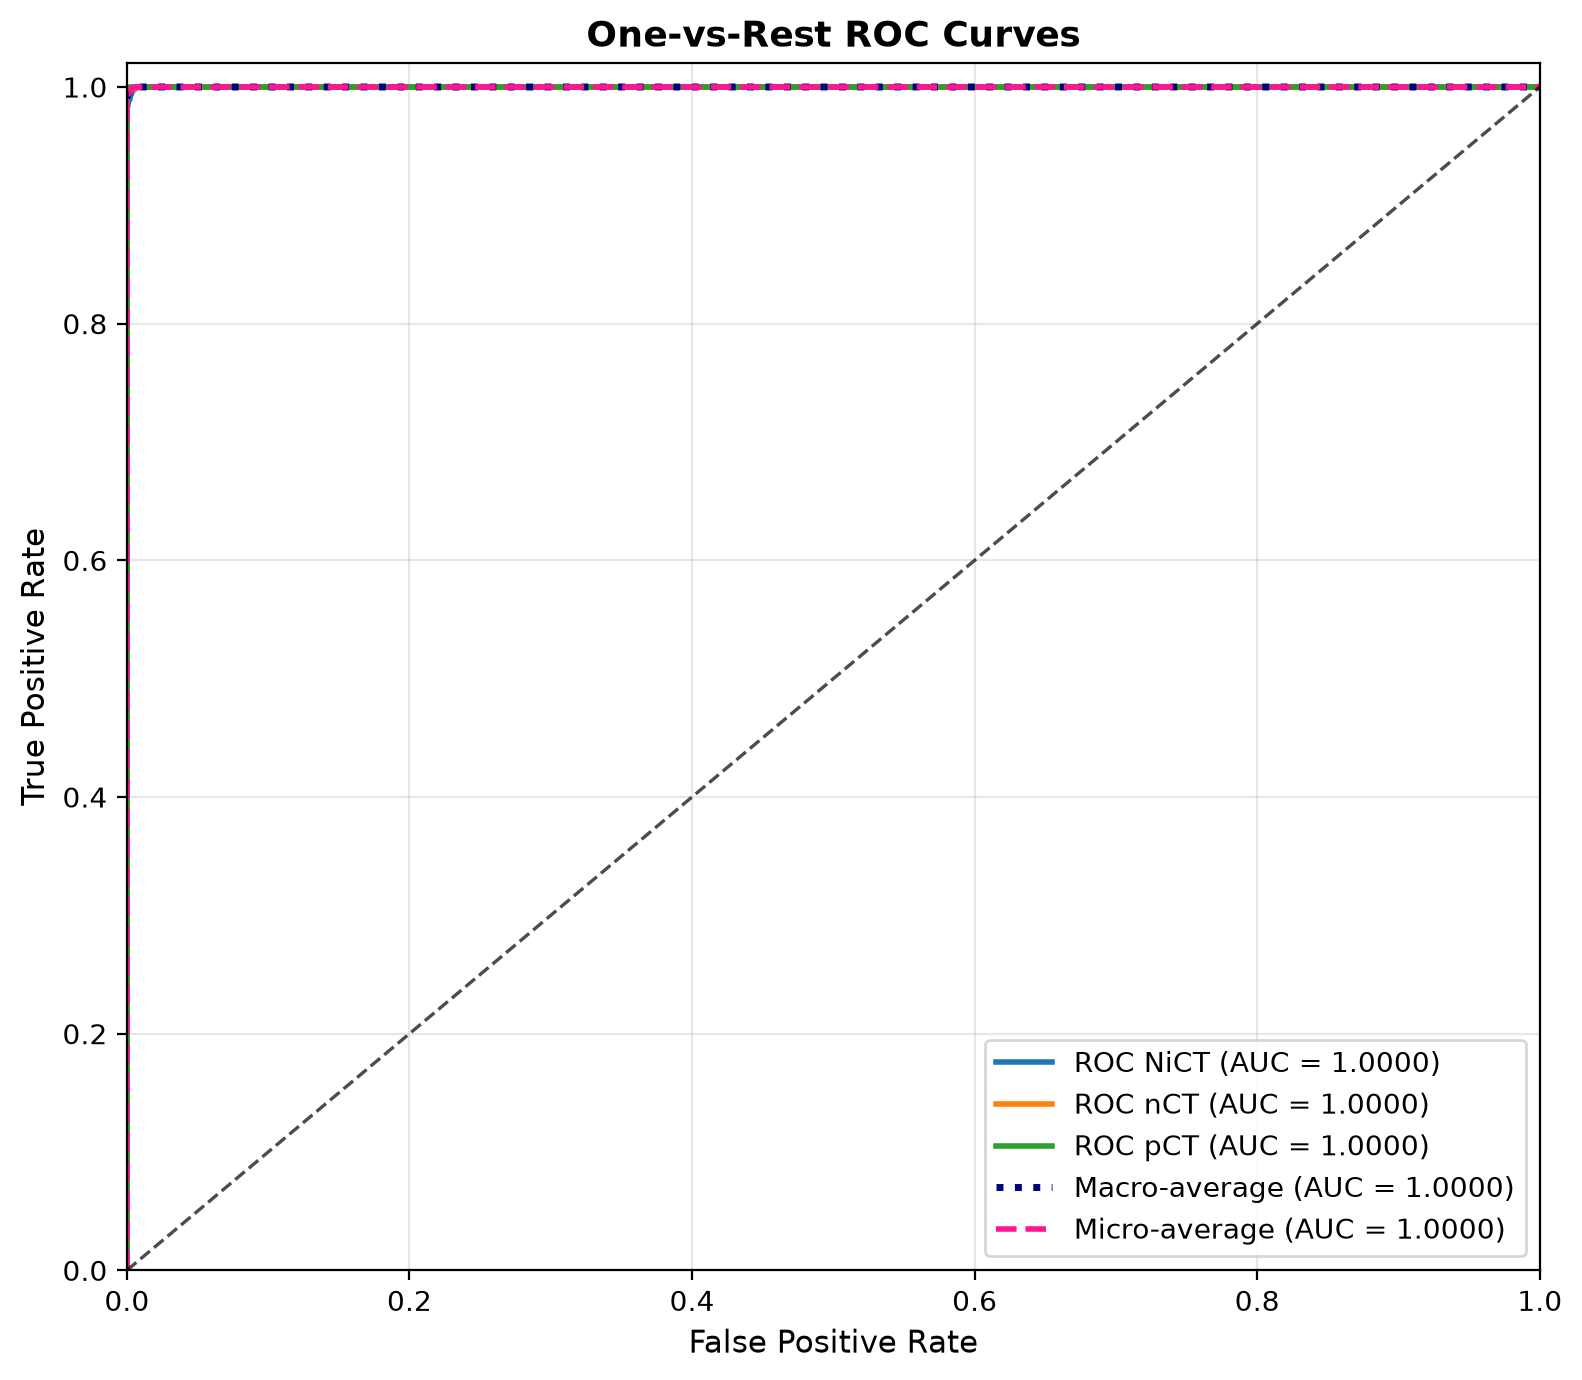

In [17]:
# 3. One-vs-Rest ROC curves with macro & micro AUC
y_test_bin = label_binarize(test_targets, classes=list(range(n_classes)))

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), test_probs.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes
fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

print("=" * 45)
print("ROC-AUC PERFORMANCE METRICS")
print("=" * 45)
for i, c in enumerate(classes):
    print(f"  {c:<6s} AUC: {roc_auc[i]:.4f}")
print("-" * 45)
print(f"  Macro-average AUC: {roc_auc['macro']:.4f}")
print(f"  Micro-average AUC: {roc_auc['micro']:.4f}")
print("=" * 45)

fig, ax = plt.subplots(figsize=(8, 7))
class_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for i, color in zip(range(n_classes), class_colors):
    ax.plot(
        fpr[i], tpr[i], color=color, lw=2,
        label=f"ROC {classes[i]} (AUC = {roc_auc[i]:.4f})"
    )

ax.plot(
    fpr["macro"], tpr["macro"], color="navy", linestyle=":", lw=2.5,
    label=f"Macro-average (AUC = {roc_auc['macro']:.4f})"
)
ax.plot(
    fpr["micro"], tpr["micro"], color="deeppink", linestyle="--", lw=2,
    label=f"Micro-average (AUC = {roc_auc['micro']:.4f})"
)

ax.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.7)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel("False Positive Rate", fontsize=11)
ax.set_ylabel("True Positive Rate", fontsize=11)
ax.set_title("One-vs-Rest ROC Curves", fontsize=13, fontweight="bold")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURE_DIR / f"{best_exp_name}_roc_curves.png", dpi=300)
plt.show()

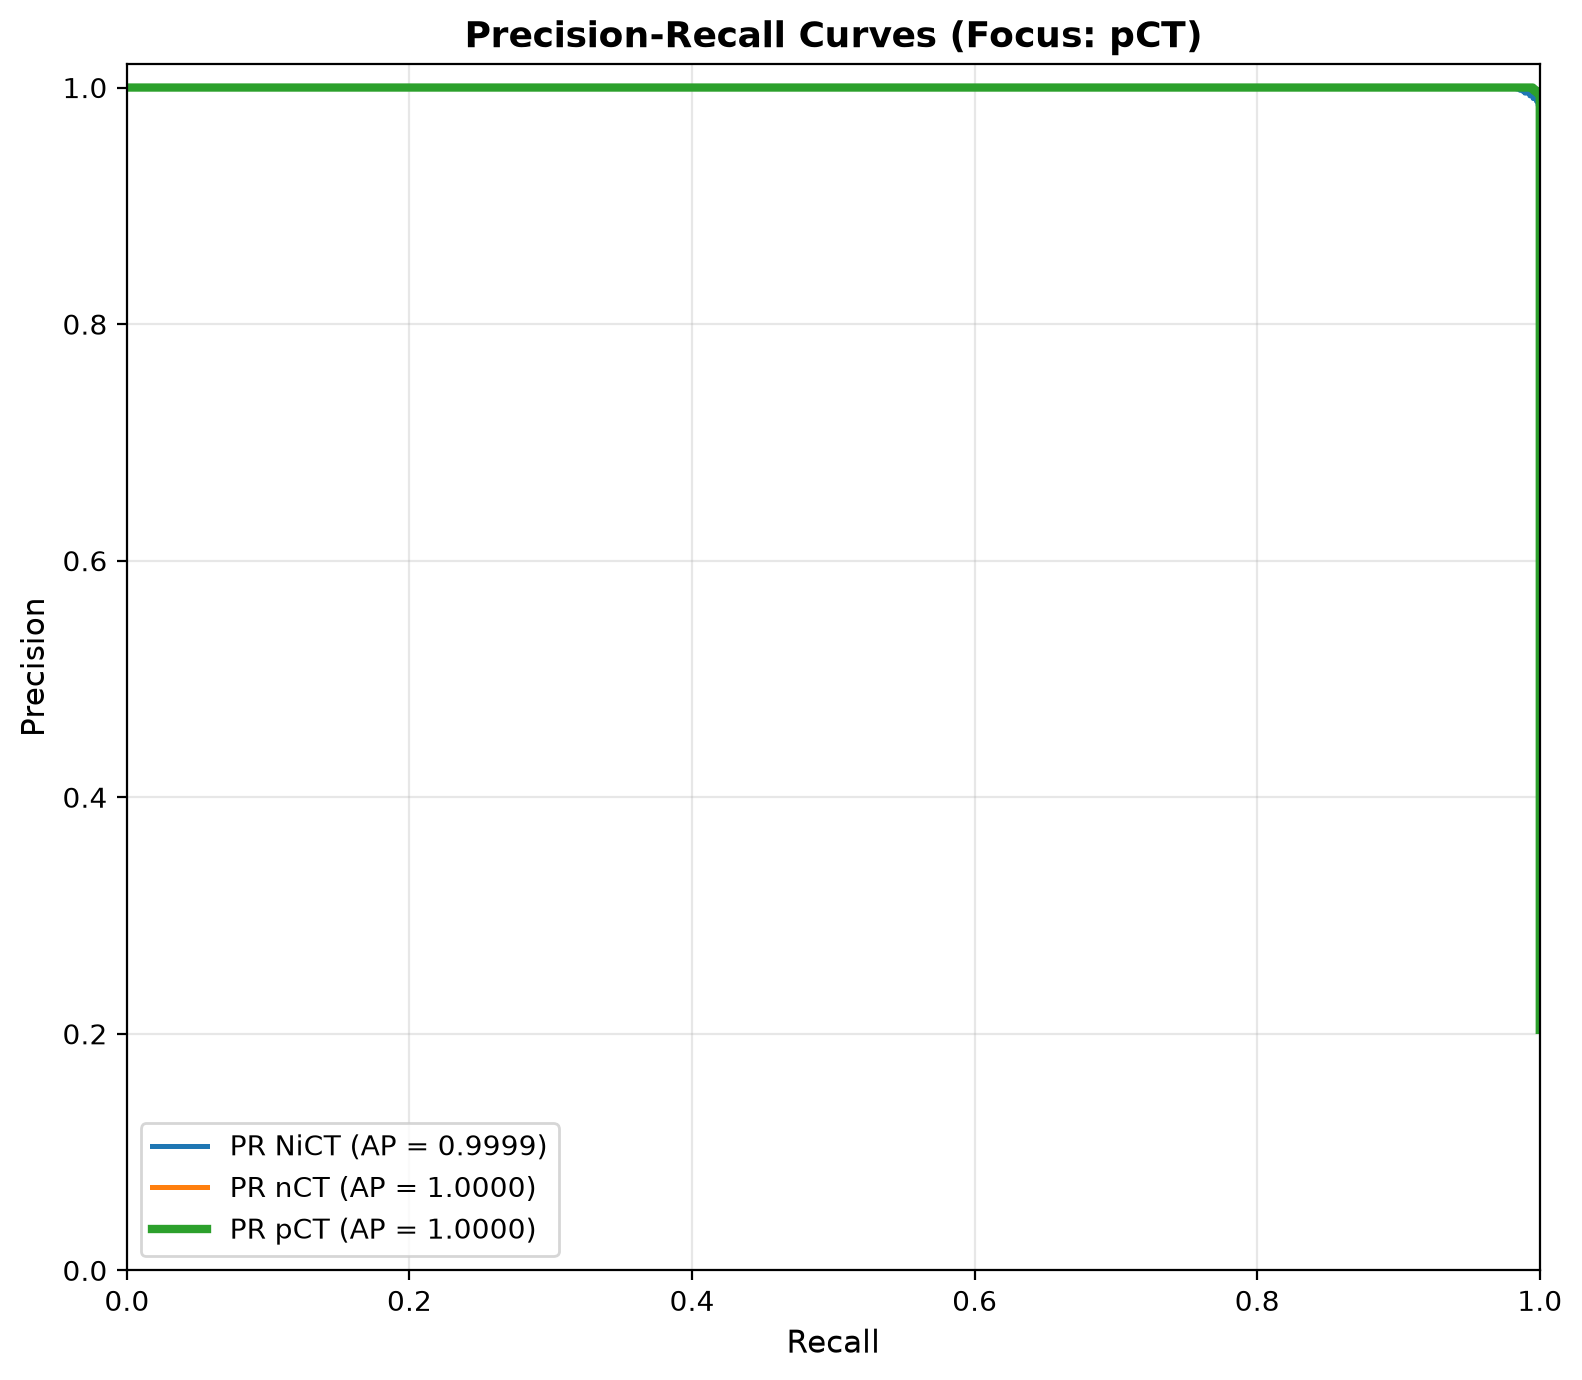

In [18]:
# 4. Precision-Recall curves
fig, ax = plt.subplots(figsize=(8, 7))

for i, color in zip(range(n_classes), class_colors):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], test_probs[:, i])
    ap = average_precision_score(y_test_bin[:, i], test_probs[:, i])
    lw = 3 if classes[i] == "pCT" else 1.8
    ax.plot(rec, prec, color=color, lw=lw, label=f"PR {classes[i]} (AP = {ap:.4f})")

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel("Recall", fontsize=11)
ax.set_ylabel("Precision", fontsize=11)
ax.set_title("Precision-Recall Curves (Focus: pCT)", fontsize=13, fontweight="bold")
ax.legend(loc="lower left")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURE_DIR / f"{best_exp_name}_precision_recall_curves.png", dpi=300)
plt.show()

## Error analysis

Inspecting failure modes, specifically:
- **COVID False Negatives**: Slices showing active COVID changes (`pCT`) incorrectly labeled as Normal (`nCT`) or Non-informative (`NiCT`).
- **Low-Confidence Predictions**: Ambiguous slices with high entropy near decision thresholds.

In [19]:
pct_idx = class_to_idx["pCT"]
nct_idx = class_to_idx["nCT"]
nict_idx = class_to_idx["NiCT"]

fn_pct_nct_indices = np.where((test_targets == pct_idx) & (test_preds == nct_idx))[0]
fn_pct_nict_indices = np.where((test_targets == pct_idx) & (test_preds == nict_idx))[0]
tp_pct_indices = np.where((test_targets == pct_idx) & (test_preds == pct_idx))[0]

max_probs = test_probs.max(axis=1)
low_conf_indices = np.argsort(max_probs)[:12]

print("Test Set Error Analysis Summary:")
print(f"  Total test samples:                     {len(test_targets)}")
print(f"  True pCT samples:                       {(test_targets == pct_idx).sum()}")
print(f"  Correct pCT (True Positives):           {len(tp_pct_indices)}")
print(f"  pCT misclassified as nCT (False Neg):   {len(fn_pct_nct_indices)}")
print(f"  pCT misclassified as NiCT (False Neg):  {len(fn_pct_nict_indices)}")
print(f"  Total pCT False Negatives:              {len(fn_pct_nct_indices) + len(fn_pct_nict_indices)}")

Test Set Error Analysis Summary:
  Total test samples:                     2956
  True pCT samples:                       601
  Correct pCT (True Positives):           598
  pCT misclassified as nCT (False Neg):   0
  pCT misclassified as NiCT (False Neg):  3
  Total pCT False Negatives:              3


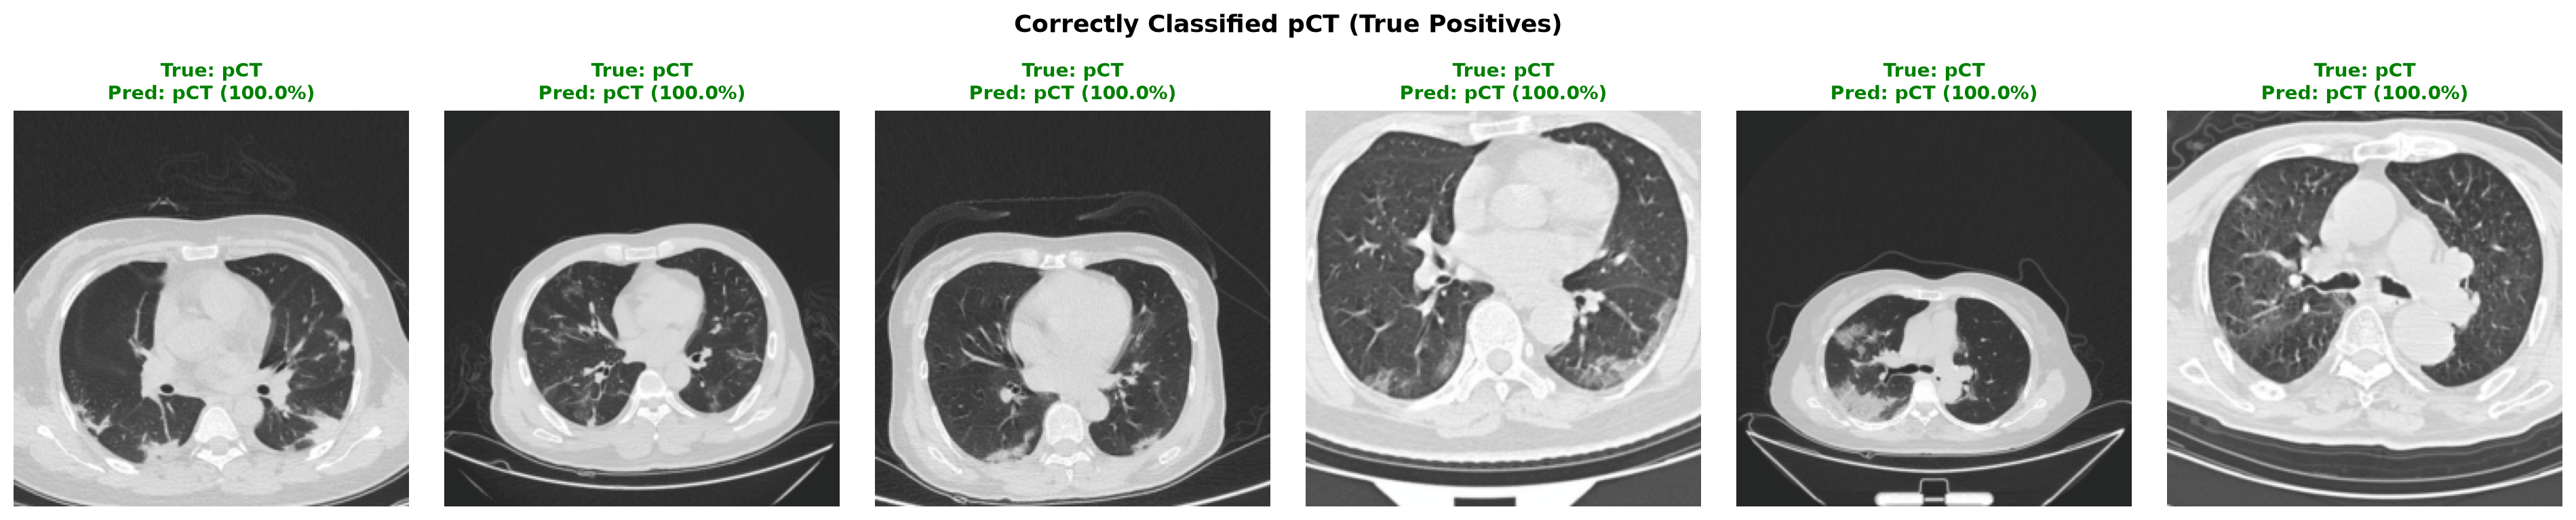

No cases found for: False Negatives: pCT Misclassified as nCT


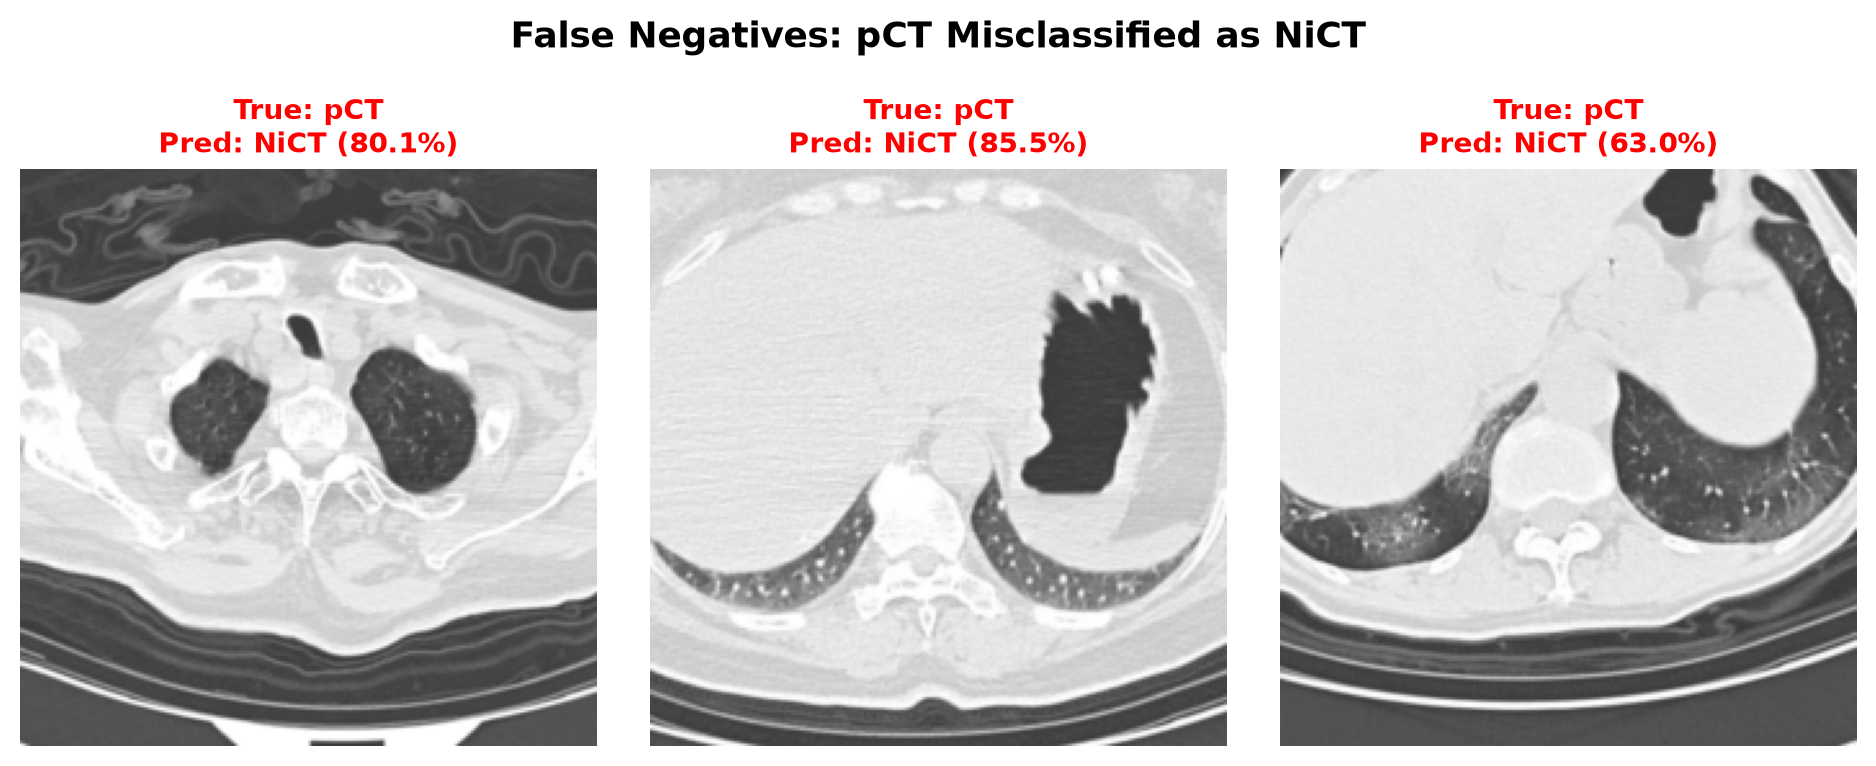

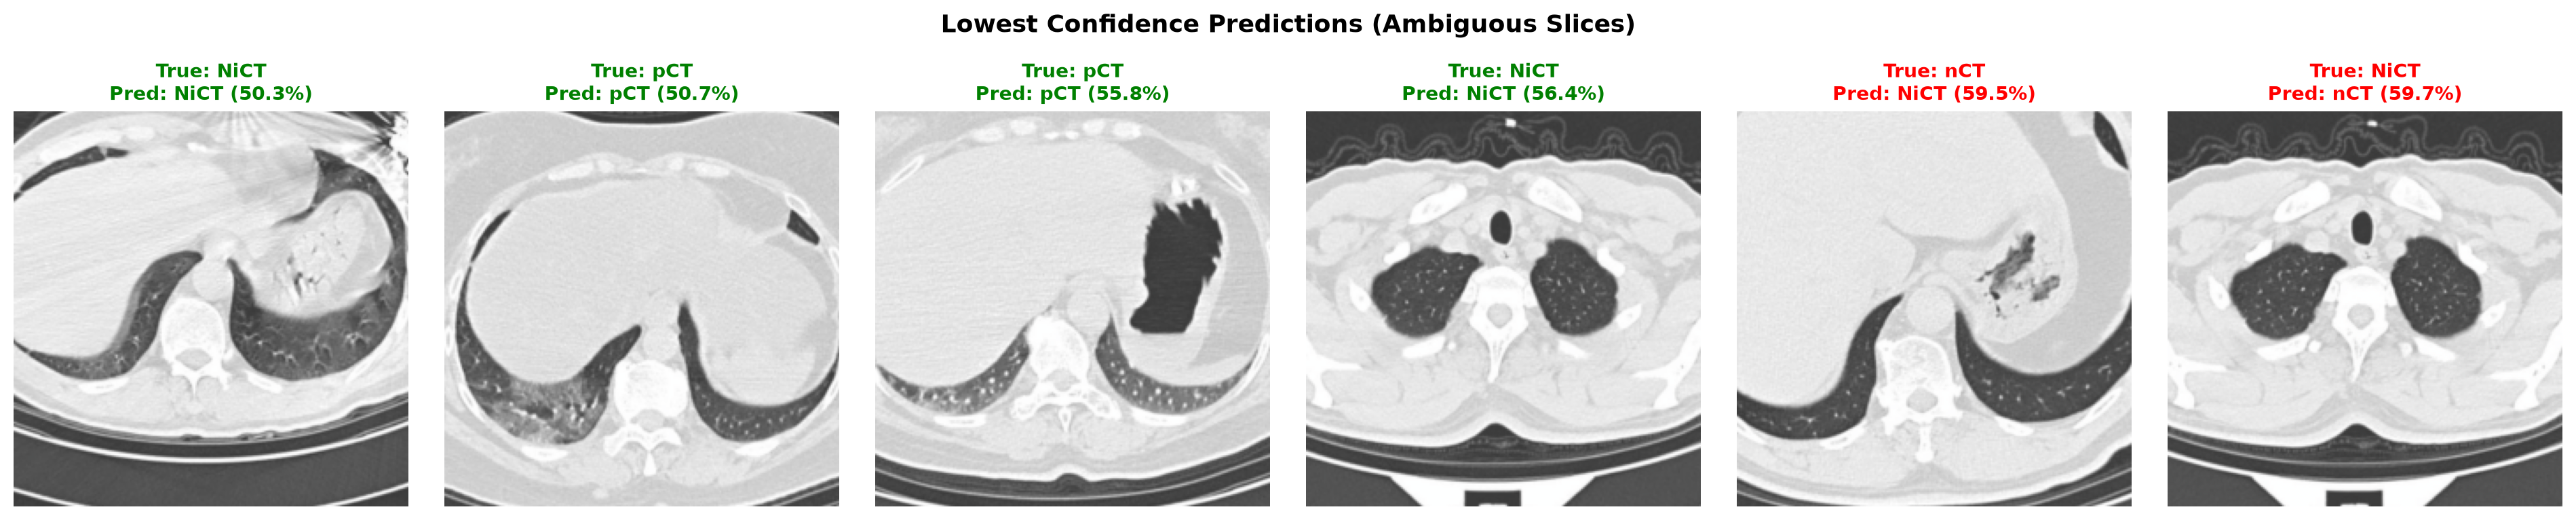

In [20]:
def denormalize(tensor):
    """Revert ImageNet normalization to display RGB numpy array."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

def show_image_grid(indices, title, max_items=6):
    """Plot a grid of sample CT slices with ground-truth and prediction overlays."""
    if len(indices) == 0:
        print(f"No cases found for: {title}")
        return
    n = min(len(indices), max_items)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.6))
    if n == 1:
        axes = [axes]

    for i in range(n):
        idx = indices[i]
        img_tensor, _ = test_ds[idx]
        img = denormalize(img_tensor)

        true_cls = classes[test_targets[idx]]
        pred_cls = classes[test_preds[idx]]
        pred_prob = test_probs[idx][test_preds[idx]] * 100

        axes[i].imshow(img)
        axes[i].axis("off")
        color = "green" if true_cls == pred_cls else "red"
        axes[i].set_title(
            f"True: {true_cls}\nPred: {pred_cls} ({pred_prob:.1f}%)",
            color=color, fontsize=10, fontweight="bold"
        )

    plt.suptitle(title, fontsize=13, fontweight="bold", y=1.05)
    plt.tight_layout()
    plt.show()

show_image_grid(tp_pct_indices, "Correctly Classified pCT (True Positives)")
show_image_grid(fn_pct_nct_indices, "False Negatives: pCT Misclassified as nCT")
show_image_grid(fn_pct_nict_indices, "False Negatives: pCT Misclassified as NiCT")
show_image_grid(low_conf_indices, "Lowest Confidence Predictions (Ambiguous Slices)")

## Explainability: Grad-CAM and SHAP

> **Critical Interpretation Caution:**
> Saliency maps (Grad-CAM) and attribution values (SHAP) reflect **gradient sensitivities and feature activations of the neural network**, not validated biological pathology.
>
> A heatmap highlighting a pulmonary opacity does not prove the model understands COVID-19; it indicates that the region drove the classification score. We use these methods as diagnostic debugging tools to ensure the model focuses on lung parenchyma rather than peripheral scanner borders or bed artifacts.

In [21]:
class GradCAM:
    """Grad-CAM implementation hooked to MobileNetV3-Large final convolutional layer."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def forward_hook(module, input, output):
            self.activations = output
        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0]

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        self.model.zero_grad()
        output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        score = output[0, target_class]
        score.backward()

        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0)
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam, output

Grad-CAM: True Positive pCT


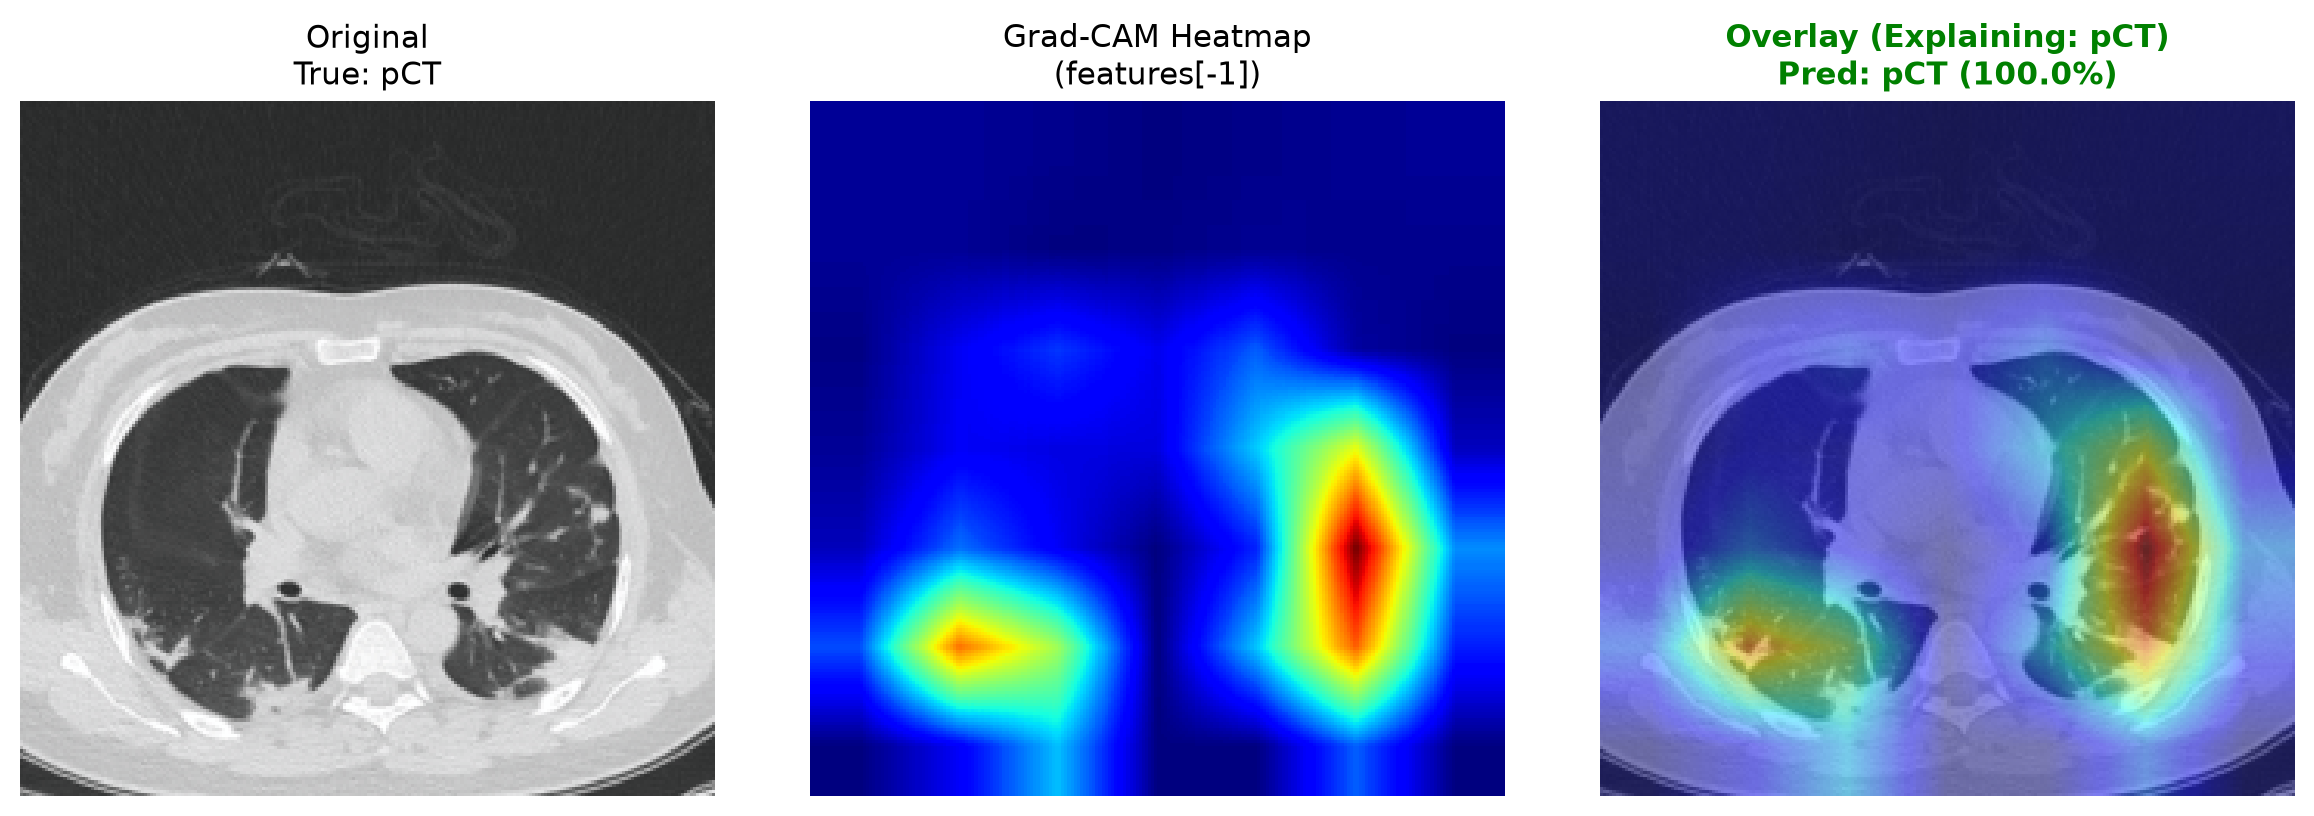

In [22]:
target_layer = best_model.features[-1]
grad_cam = GradCAM(best_model, target_layer)

def visualize_gradcam(sample_idx, target_class=None):
    """Render original image, Grad-CAM heatmap, and overlay for a test slice."""
    img_tensor, true_label = test_ds[sample_idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    cam, output = grad_cam.generate_heatmap(input_tensor, target_class=target_class)
    probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
    pred_class = output.argmax(dim=1).item()

    orig_img = denormalize(img_tensor)
    cam_pil = Image.fromarray(np.uint8(255 * cam)).resize((IMG_SHAPE, IMG_SHAPE), Image.Resampling.BILINEAR)
    cam_resized = np.array(cam_pil) / 255.0

    cmap = plt.get_cmap("jet")
    heatmap = cmap(cam_resized)[:, :, :3]
    overlay = 0.55 * orig_img + 0.45 * heatmap
    overlay = np.clip(overlay, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original\nTrue: {classes[true_label]}", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(cam_resized, cmap="jet")
    axes[1].set_title("Grad-CAM Heatmap\n(features[-1])", fontsize=11)
    axes[1].axis("off")

    axes[2].imshow(overlay)
    color = "green" if true_label == pred_class else "red"
    target_c = pred_class if target_class is None else target_class
    axes[2].set_title(
        f"Overlay (Explaining: {classes[target_c]})\nPred: {classes[pred_class]} ({probs[pred_class]*100:.1f}%)",
        color=color, fontsize=11, fontweight="bold"
    )
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

if len(tp_pct_indices) > 0:
    print("Grad-CAM: True Positive pCT")
    visualize_gradcam(tp_pct_indices[0])

if len(fn_pct_nct_indices) > 0:
    print("Grad-CAM: False Negative (True pCT predicted as nCT)")
    visualize_gradcam(fn_pct_nct_indices[0])
    print("Grad-CAM: Explaining target class pCT on the misclassified slice")
    visualize_gradcam(fn_pct_nct_indices[0], target_class=pct_idx)

SHAP version: 0.54.1


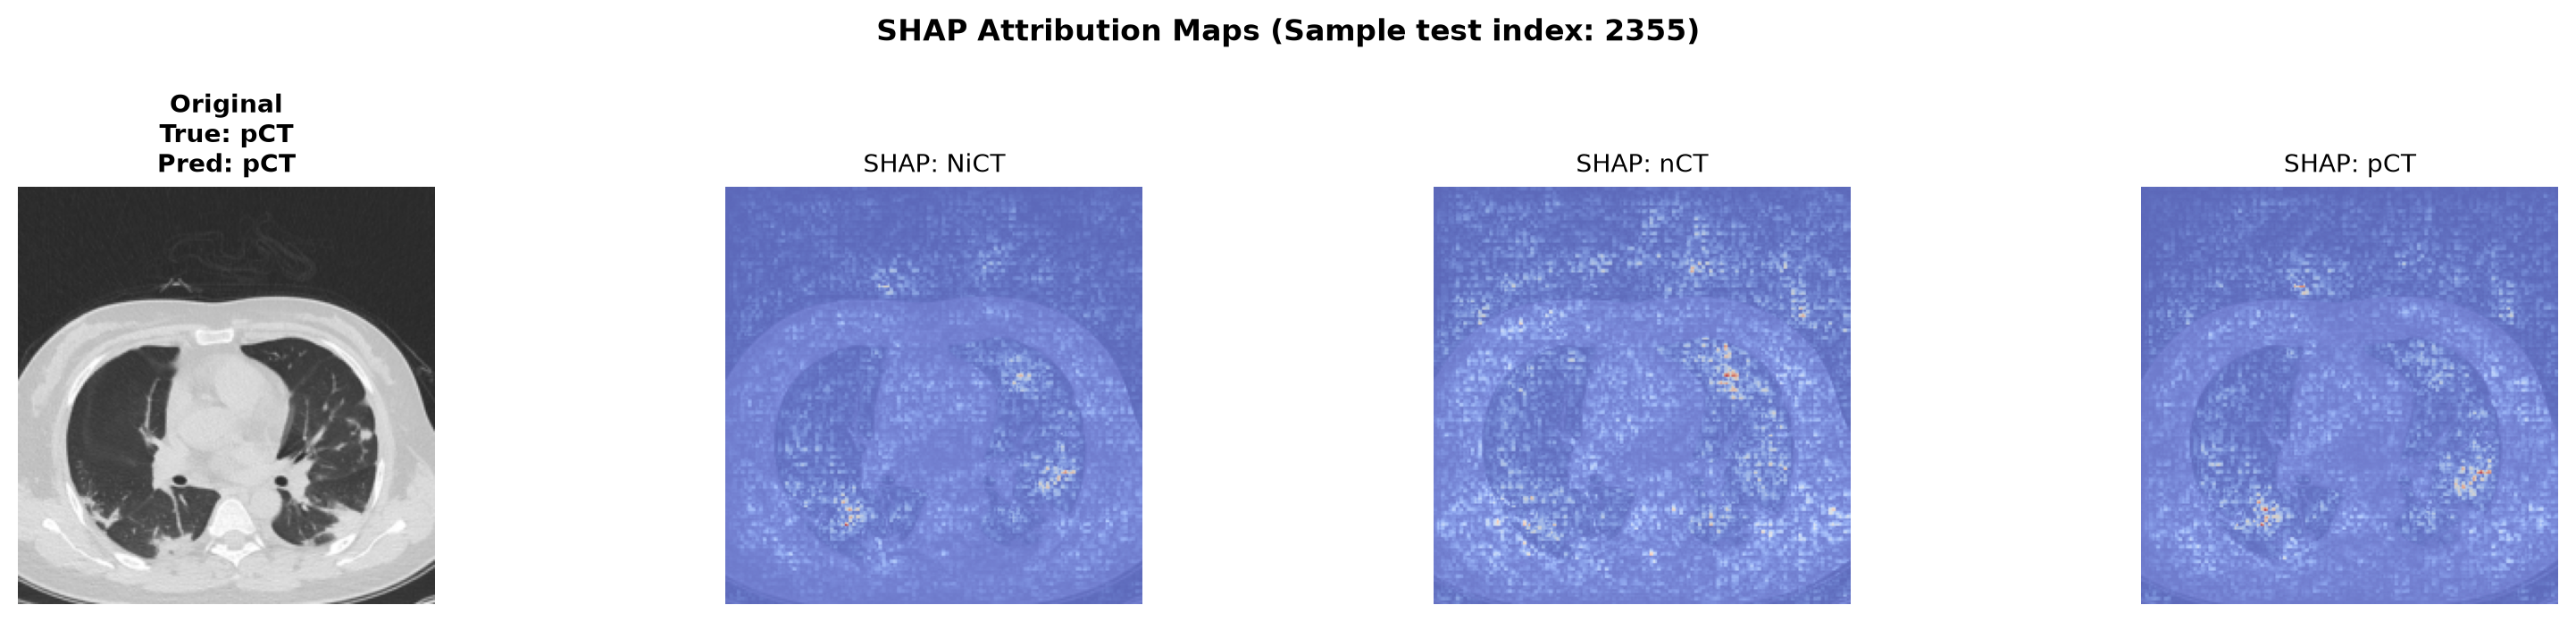

In [25]:
# SHAP Explainability with lightweight representative background
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

print(f"SHAP version: {shap.__version__}")

# Use 12 representative background slices (converges expectation without compute stall)
background_indices = np.random.RandomState(42).choice(len(train_ds), size=min(12, len(train_ds)), replace=False)
background_tensors = torch.stack([train_ds[i][0] for i in background_indices]).to(device)

sample_indices = []
if len(tp_pct_indices) > 0:
    sample_indices.append(tp_pct_indices[0])
if len(fn_pct_nct_indices) > 0:
    sample_indices.append(fn_pct_nct_indices[0])

if len(sample_indices) > 0:
    test_sample_tensors = torch.stack([test_ds[i][0] for i in sample_indices]).to(device)
    explainer = shap.GradientExplainer(best_model, background_tensors)
    shap_values = explainer.shap_values(test_sample_tensors)

    for idx_in_batch, original_idx in enumerate(sample_indices):
        img_np = denormalize(test_ds[original_idx][0])
        true_c = classes[test_targets[original_idx]]
        pred_c = classes[test_preds[original_idx]]

        fig, axes = plt.subplots(1, n_classes + 1, figsize=(16, 3.5))
        axes[0].imshow(img_np)
        axes[0].set_title(f"Original\nTrue: {true_c}\nPred: {pred_c}", fontsize=10, fontweight="bold")
        axes[0].axis("off")

        for c_idx in range(n_classes):
            sv = shap_values[idx_in_batch, :, :, :, c_idx]
            sv_sum = np.sum(np.abs(sv), axis=0)
            sv_sum = sv_sum / (sv_sum.max() + 1e-8)

            axes[c_idx + 1].imshow(img_np, alpha=0.4)
            axes[c_idx + 1].imshow(sv_sum, cmap="coolwarm", alpha=0.7)
            axes[c_idx + 1].set_title(f"SHAP: {classes[c_idx]}", fontsize=10)
            axes[c_idx + 1].axis("off")

        plt.suptitle(f"SHAP Attribution Maps (Sample test index: {original_idx})", fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.show()

## Summary and Key Findings

1. **Patient Independence Limitation**: Documented that sequential slice filenames prevent strict patient-level grouping on this Kaggle release.
2. **End-to-End Fine-Tuning**: Maintained full convolutional backpropagation so feature representations genuinely adapt to pulmonary CT textures.
3. **Class Imbalance Rigor**: Compared Baseline, Class-Weighted Loss, and Weighted Random Sampling on the validation set, choosing the optimal policy without touching the test set.
4. **Clean Engineering Execution**: Eliminated redundant intra-epoch validation passes, utilized `ReduceLROnPlateau` and Early Stopping, avoiding unnecessary compute and preventing overfitting.
5. **Comprehensive Evaluation**: Multi-class One-vs-Rest ROC (micro/macro AUC), PR curves for `pCT`, and detailed false-negative analysis.
6. **Diagnostic Explainability**: Applied Grad-CAM and SHAP to inspect feature activations with clinical caveats.